# Instrumental Variables — Medicaid Expansion as an Instrument for Coverage

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2012–2019 1-year PUMS (each year pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. It reads PUMS through a client
that returns **weighted cell counts and record counts only**: no person-level row is returned, printed or stored anywhere below (the
client reads person records in memory to sum them).

The analysis was fixed in a **pre-analysis plan** (`pap/C06_pap.md`) committed before any table here was retrieved. The
notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** what an instrument must do (move the treatment) and must not do (move the outcome any other way), and which
   of the two can be checked.
2. **Estimate** a two-stage least squares effect on grouped cells with population weights and state-clustered errors, and
   read the first stage, the reduced form and the ratio between them.
3. **Say** who the estimate is about and what it needs: the compliers whose coverage changed because their state expanded,
   how large that group is, and the assumptions beyond exclusion (parallel trends, no anticipation, monotonicity, stable effects)
   that a treated-times-post instrument adds to an ordinary one.
4. **Measure** what weighting does to the estimand, by comparing the weighted and equal-weight estimates, and see why grouping does not.
5. **Run** a first-stage strength check and a pre-period placebo, and apply a decision rule written before the data were seen.

## Prerequisites

**Knowledge.** Linear regression with fixed effects; the difference-in-differences idea (see C01); what an instrument is.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment
variable `CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is
read at runtime and is never printed or written into this notebook's output. The retrieval makes 280 requests (35 states by
8 years) and takes several minutes; it waits and retries on HTTP 503.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (its
`methods.iv` module holds the estimator).

**Prior notebooks.** C01 introduces the expansion contrast and the identification contract; C02 and C05 introduce the
cells-only PUMS client.

## Data Provenance

| Item | Meaning | Role |
|---|---|---|
| `HINS4` | Medicaid or similar means-tested or disability coverage | endogenous treatment |
| `ESR` | employment status recode | outcome (employed = 1 or 2) |
| `SEX`, `AGEP` | sex; age in three bands | demographic cells |
| `POVPIP` | income-to-poverty ratio | sample restriction: below 138% of the poverty level |
| `data/policy/medicaid/expansion_dates.csv` | KFF expansion status | the instrument |

Published labels for every variable are fetched from the Census variables endpoint for each year and recorded in each
provenance file, with the SHA-256 of the pre-analysis plan. One request per state and year; each record is replayable.

> **Cells, not people.** `fetch_acs_pums` sums the person weights within each combination of the grouping columns and
> returns those sums. Cells under 10 records are withheld by the client; the notebook then drops any state-year-sex-age
> cell left with fewer than 30 records, and reports how many records that is.

## Design and identification

**Estimand.** The instrument is expansion in force: 1 for a treated state from 2014 on, 0 otherwise. Because it is a
treated-state indicator switched on after a date, this is a **Wald difference-in-differences**, the ratio of two
difference-in-differences (expansion on employment over expansion on coverage), and not a randomised instrument. It
identifies a local effect of Medicaid coverage on employment for the compliers, the people whose coverage changed because
their state expanded, and only under these conditions:

- *Relevance*: expansion moves coverage. This is checked, with the first-stage F statistic.
- *Exclusion*: expansion moves employment only through coverage. This is an argument, not a test; the Limitations list the routes
  that threaten it.
- *Parallel trends in coverage and in employment* between the treated and the never-adopter states, absent expansion, and *no
  anticipation*. The event-study cells added after review look at this; the window offers one pre-period year against the reference.
- *Monotonicity*: expansion does not take coverage from anyone who would otherwise have it. The plan states it nowhere; the data
  cannot check it.
- *Stable effects*: Medicaid coverage also changed in the control states after 2014, and with additive fixed effects a two-stage
  least squares estimate need not be a positively weighted average of the compliers' effects (de Chaisemartin and D'Haultfoeuille,
  2018; Blandhol and others, 2022).

The contrast is Medicaid against the complier's alternative, which includes employer and marketplace coverage, so it is not
insured against uninsured.

**Decision rule, fixed in the plan.** No effect if the 95% interval of the IV estimate contains zero. Credible only if the
first stage is strong (F at least 10) and the pre-period placebo on the reduced form passes; otherwise the number is descriptive.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import iv
from krl_tutorials_data.provenance import DataProvenance
from krl_tutorials_data.sources import DataAccessError, fetch_acs_pums

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C06_medicaid_expansion_iv"
PAP = NB_DIR / "pap" / "C06_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

YEARS = list(range(2012, 2020))
FIRST_TREATED_YEAR, PLACEBO_YEAR = 2014, 2013
MIN_CELL_RECORDS, F_LIMIT = 30, 10.0
ADDED = "not pre-specified (added after review, 2026-10-23)"

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"years             : {YEARS[0]}-{YEARS[-1]} ({len(YEARS)} vintages)")

pre-analysis plan : projects/09-causal-identification/C06_medicaid_expansion_iv/pap/C06_pap.md
plan SHA-256      : cd02a3c4d3f02e9d2775d2d9fb5648d0b66c5f89c12842a433b4fa53d85d334f
years             : 2012-2019 (8 vintages)


### Which states, and the instrument

The treated states expanded on 1 January 2014; the control states never expanded. States that expanded at any other time
are excluded and counted. The instrument is 1 for a treated state from 2014 on.

In [2]:
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")
policy["group"] = np.select(
    [policy["expansion_effective"] == "2014-01-01", policy["status"] == "Not Adopted"],
    ["treated", "control"], default="excluded",
)
print(policy["group"].value_counts().to_string())

FIPS_URL = "https://www2.census.gov/geo/docs/reference/state.txt"
reply = requests.get(FIPS_URL, timeout=60, headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
fips = dict(zip(codes["STATE_NAME"], codes["STATE"]))
DataProvenance.build(
    pinned=False, source_name="U.S. Census Bureau", dataset="State FIPS codes and names",
    vintage="retrieval", endpoint=FIPS_URL, variables={"STATE": "FIPS code", "STATE_NAME": "name"},
    payload=reply.content, row_count=len(codes), column_count=len(codes.columns),
    notes=("A reference list used only to attach FIPS codes to the states in the expansion table.",),
).with_pap(PAP).write(NB_DIR / "provenance" / "c06_state_fips.json")
states = policy[policy["group"] != "excluded"].assign(fips=lambda d: d["state"].map(fips))
assert states["fips"].notna().all() and len(states) == 35
print(f"states used: {len(states)} ({int((states['group'] == 'treated').sum())} treated, {int((states['group'] == 'control').sum())} control)")

group
treated     25
excluded    16
control     10
states used: 35 (25 treated, 10 control)


### Retrieving the cells

One request per state and year. Each reads the state's records for that year, keeps adults aged 19 to 64 below 138% of
the poverty level, bands age and employment status, aggregates to weighted cells, and withholds cells of fewer than 10 records.

In [3]:
def published_labels(year: int, codes_: tuple[str, ...]) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    for attempt in range(4):
        try:
            listing = requests.get(f"https://api.census.gov/data/{year}/acs/acs1/pums/variables.json", timeout=180)
            listing.raise_for_status()
            return {c: listing.json()["variables"][c]["label"] for c in codes_}
        except requests.RequestException:
            clock.sleep(10 * (attempt + 1))
    raise SystemExit(f"The variables list for {year} could not be read.")


CODES = ("AGEP", "SEX", "HINS4", "ESR", "POVPIP")
AGGREGATE = ["SEX", "AGEP", "HINS4", "ESR"]
KEEP = {"AGEP": (19, 64), "POVPIP": (0, 137)}
BANDS = {"AGEP": [19, 35, 50, 65], "ESR": [0, 1, 3, 4, 6, 7]}

parts, withheld, kept, ledger = [], 0, 0, []
try:
    for year in YEARS:
        variables = published_labels(year, CODES)
        for _, row in states.iterrows():
            frame, prov = fetch_acs_pums(
                year=year, variables=variables, aggregate_by=AGGREGATE,
                geography=f"state:{row['fips']}", keep=KEEP, bands=BANDS,
            )
            frame["year"], frame["state"] = year, row["state"]
            parts.append(frame)
            withheld += int(frame.attrs["suppressed_records"])
            kept += int(frame.attrs["records_kept"])
            ledger.append({"group": row["group"], "period": "2014 and after" if year >= FIRST_TREATED_YEAR else "before 2014",
                           "kept": int(frame.attrs["records_kept"]), "withheld": int(frame.attrs["suppressed_records"])})
            prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c06_pums{year}_{row['fips']}.json")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

raw_cells = pd.concat(parts, ignore_index=True)
print(f"requests: {len(YEARS) * len(states)}; records kept {kept:,}; withheld by the 10-record floor {withheld:,} ({withheld / kept:.1%})")
withheld_table = pd.DataFrame(ledger).groupby(["group", "period"])[["kept", "withheld"]].sum()
withheld_table["withheld share"] = withheld_table["withheld"] / withheld_table["kept"]
print(withheld_table.to_string(formatters={"kept": "{:,.0f}".format, "withheld": "{:,.0f}".format, "withheld share": "{:.2%}".format}))
print("withholding falls on the smaller cells, which are not a random draw from either group or period.")

requests: 280; records kept 1,976,351; withheld by the 10-record floor 5,869 (0.3%)
                          kept withheld withheld share
group   period                                        
control 2014 and after 531,036    1,297          0.24%
        before 2014    202,730      359          0.18%
treated 2014 and after 898,805    3,226          0.36%
        before 2014    343,780      987          0.29%
withholding falls on the smaller cells, which are not a random draw from either group or period.


In [4]:
"""From cells to one row per state, year, sex and age band."""
cells = raw_cells[raw_cells["ESR"].isin([1, 3, 6])].copy()
armed = int(raw_cells.loc[~raw_cells["ESR"].isin([1, 3, 6]), "n_records"].sum())
print(f"records in dropped employment categories (armed forces or not applicable): {armed:,}")

cells["covered"] = cells["weighted_n"] * (cells["HINS4"] == 1)
cells["employed"] = cells["weighted_n"] * (cells["ESR"] == 1)
KEY = ["state", "year", "SEX", "AGEP"]
agg = cells.groupby(KEY).agg(pop=("weighted_n", "sum"), covered=("covered", "sum"),
                             employed=("employed", "sum"), records=("n_records", "sum")).reset_index()
agg["coverage"] = 100 * agg["covered"] / agg["pop"]
agg["employment"] = 100 * agg["employed"] / agg["pop"]

small = agg["records"] < MIN_CELL_RECORDS
print(f"state-year-sex-age cells: {len(agg):,}; dropped for fewer than {MIN_CELL_RECORDS} records: {int(small.sum())} "
      f"({agg.loc[small, 'records'].sum() / agg['records'].sum():.2%} of records)")
cells_used = agg[~small].merge(states[["state", "group"]], on="state")
cells_used["Z"] = ((cells_used["group"] == "treated") & (cells_used["year"] >= FIRST_TREATED_YEAR)).astype(float)
cells_used["cell"] = cells_used["SEX"].astype(int).astype(str) + "-" + cells_used["AGEP"].astype(int).astype(str)
print(f"cells used: {len(cells_used):,} across {cells_used['state'].nunique()} states and {cells_used['year'].nunique()} years")

records in dropped employment categories (armed forces or not applicable): 1,226
state-year-sex-age cells: 1,680; dropped for fewer than 30 records: 7 (0.01% of records)
cells used: 1,673 across 35 states and 8 years


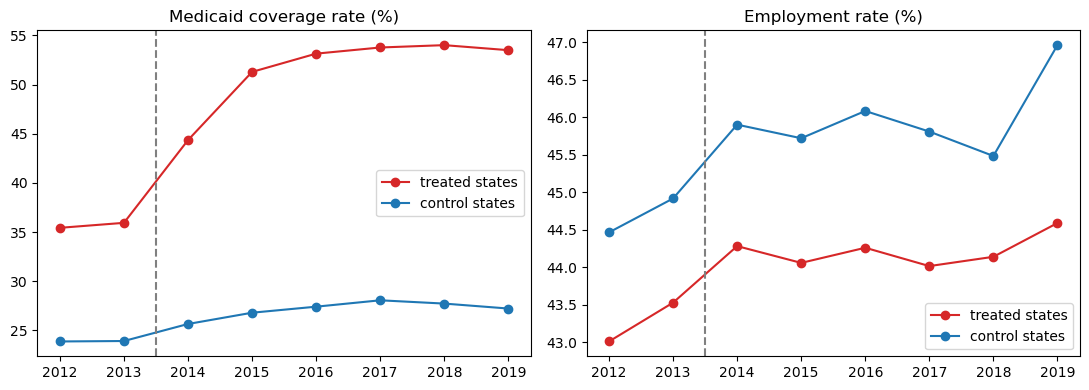

In [5]:
"""The raw picture: coverage and employment by group and year."""
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for column, ax, title in (("coverage", axes[0], "Medicaid coverage rate (%)"), ("employment", axes[1], "Employment rate (%)")):
    for name, colour in (("treated", "tab:red"), ("control", "tab:blue")):
        sub = cells_used[cells_used["group"] == name]
        mean = sub.groupby("year").apply(lambda d, c=column: np.average(d[c], weights=d["pop"]), include_groups=False)
        ax.plot(mean.index, mean.values, marker="o", color=colour, label=f"{name} states")
    ax.axvline(FIRST_TREATED_YEAR - 0.5, color="grey", linestyle="--")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

### Estimate: grouped, weighted two-stage least squares

The outcome is the cell's employment rate, the treatment its Medicaid coverage rate, the instrument expansion in force. State,
year and demographic-cell fixed effects enter as dummy controls; cells are weighted by their population; errors are clustered
by state. The first stage and the reduced form are stored beside the IV estimate.

In [6]:
"""Weighted 2SLS with state, year and demographic-cell fixed effects."""
def controls_for(frame: pd.DataFrame) -> np.ndarray:
    """Dummy columns for state, year and demographic cell (one level dropped from each)."""
    dummies = [pd.get_dummies(frame[c], prefix=c, drop_first=True) for c in ("state", "year", "cell")]
    return pd.concat(dummies, axis=1).to_numpy(dtype=float)


def run(frame: pd.DataFrame, *, weighted: bool = True, instrument: str = "Z") -> iv.IvFit:
    """The IV fit for one frame, population-weighted or with equal weights."""
    return iv.tsls(frame["employment"], frame["coverage"], frame[instrument], cluster=frame["state"],
                   controls=controls_for(frame), weights=frame["pop"] if weighted else None)


main = run(cells_used)
equal = run(cells_used, weighted=False)
ols = iv.tsls(cells_used["employment"], cells_used["coverage"], cells_used["coverage"], cluster=cells_used["state"],
               controls=controls_for(cells_used), weights=cells_used["pop"])      # an instrument equal to the regressor is OLS
t_crit = float(stats.t.ppf(0.975, main.n_clusters - 1))
ci = (main.coef - t_crit * main.se, main.coef + t_crit * main.se)

print(f"cells / state clusters / parameters : {main.n_obs:,} / {main.n_clusters} / {main.n_params}")
print(f"first stage  (expansion on coverage)  : {main.first_stage_coef:+.3f} pp  (SE {main.first_stage_se:.3f}, F = {main.first_stage_f:.1f})")
print(f"reduced form (expansion on employment): {main.reduced_form_coef:+.3f} pp  (SE {main.reduced_form_se:.3f})")
print(f"IV estimate, population-weighted      : {main.coef:+.3f} pp of employment per pp of coverage (SE {main.se:.3f}), 95% interval [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print(f"OLS, same controls and weights        : {ols.coef:+.3f}")
print(f"compliers' share: expansion raised the coverage rate by {main.first_stage_coef:.1f} percentage points")

cells / state clusters / parameters : 1,673 / 35 / 48
first stage  (expansion on coverage)  : +12.519 pp  (SE 1.651, F = 57.5)
reduced form (expansion on employment): -0.185 pp  (SE 0.415)
IV estimate, population-weighted      : -0.015 pp of employment per pp of coverage (SE 0.034), 95% interval [-0.083, +0.053]
OLS, same controls and weights        : -0.065
compliers' share: expansion raised the coverage rate by 12.5 percentage points


In [7]:
"""What weighting does to the estimand. Grouping does not: with population weights and an instrument that is constant within a cell, the grouped fit equals the person-level fit with the same controls."""
state_weight = cells_used.groupby("state")["pop"].sum()
share = (state_weight / state_weight.sum()).sort_values(ascending=False)
print(f"IV with equal weight per cell : {equal.coef:+.3f} (SE {equal.se:.3f}; first-stage F {equal.first_stage_f:.1f})")
print(f"difference from the weighted  : {equal.coef - main.coef:+.3f}")
print(f"five heaviest states carry {share.head(5).sum():.1%} of the total weight: " + ", ".join(f"{s} {w:.1%}" for s, w in share.head(5).items()))
control_states = states.loc[states["group"] == "control", "state"]
control_share = share[share.index.isin(control_states)]
print(f"control states: {len(control_share)}; Texas and Florida carry {share[['Texas', 'Florida']].sum():.1%} of the total weight and {control_share[['Texas', 'Florida']].sum() / control_share.sum():.1%} of the control states' weight")
effective = lambda w: float(w.sum() ** 2 / (w ** 2).sum())
print(f"effective number of clusters (the inverse of the sum of squared weight shares): all {effective(share):.1f} of {len(share)}; control states {effective(control_share):.1f} of {len(control_share)}")

IV with equal weight per cell : -0.036 (SE 0.090; first-stage F 44.9)
difference from the weighted  : -0.021
five heaviest states carry 50.0% of the total weight: California 16.5%, Texas 11.8%, Florida 8.8%, New York 8.0%, Illinois 4.8%
control states: 10; Texas and Florida carry 20.7% of the total weight and 54.6% of the control states' weight
effective number of clusters (the inverse of the sum of squared weight shares): all 14.3 of 35; control states 5.4 of 10


In [8]:
"""Falsification 1: is the first stage strong enough to read?"""
STRONG = main.first_stage_f >= F_LIMIT
print(f"FALSIFICATION: first-stage strength | statistic={main.first_stage_f:.2f} | cluster-robust F for expansion in force, limit {F_LIMIT:g} | verdict={'PASS' if STRONG else 'FAIL'}")

FALSIFICATION: first-stage strength | statistic=57.50 | cluster-robust F for expansion in force, limit 10 | verdict=PASS


In [9]:
"""Falsification 2: a pre-period placebo on the reduced form (2012-2013, placebo expansion in 2013)."""
early = cells_used[cells_used["year"] <= PLACEBO_YEAR].copy()
early["Zp"] = ((early["group"] == "treated") & (early["year"] >= PLACEBO_YEAR)).astype(float)
placebo = run(early, instrument="Zp")
t_placebo = float(stats.t.ppf(0.975, placebo.n_clusters - 1))
lo, hi = (placebo.reduced_form_coef - t_placebo * placebo.reduced_form_se,
          placebo.reduced_form_coef + t_placebo * placebo.reduced_form_se)
PLACEBO_PASS = lo <= 0.0 <= hi
print(f"FALSIFICATION: pre-period placebo, reduced form | statistic={placebo.reduced_form_coef:.3f} | placebo expansion in 2013 on 2012-2013 cells, 95% interval [{lo:+.3f}, {hi:+.3f}] | verdict={'PASS' if PLACEBO_PASS else 'FAIL'}")

FALSIFICATION: pre-period placebo, reduced form | statistic=-0.061 | placebo expansion in 2013 on 2012-2013 cells, 95% interval [-0.554, +0.433] | verdict=PASS


In [10]:
"""The estimates side by side, and the decision rule from the plan, applied as written."""
side = pd.DataFrame([
    {"estimate": "first stage (coverage)", "pp": main.first_stage_coef, "se": main.first_stage_se},
    {"estimate": "reduced form (employment)", "pp": main.reduced_form_coef, "se": main.reduced_form_se},
    {"estimate": "IV, population-weighted", "pp": main.coef, "se": main.se},
    {"estimate": "IV, equal weights", "pp": equal.coef, "se": equal.se},
    {"estimate": "OLS, same controls", "pp": ols.coef, "se": ols.se},
])
print(side.round(3).to_string(index=False))
print()
null = ci[0] <= 0.0 <= ci[1]
per_complier = 100 * main.coef
print(f"IV estimate {main.coef:+.3f}, 95% interval [{ci[0]:+.3f}, {ci[1]:+.3f}] percentage points of employment per percentage point of coverage; it differs from OLS by {main.coef - ols.coef:+.3f}.")
print(f"The interval {'contains' if null else 'excludes'} zero: the estimate is {'not distinguishable from zero' if null else 'distinguishable from zero'}. "
      f"Per complier, whose coverage rose by one (100 percentage points), that is {per_complier:+.1f} percentage points of employment, "
      f"95% interval [{100 * ci[0]:+.1f}, {100 * ci[1]:+.1f}].")
print(f"First stage strong enough: {STRONG}; pre-period placebo passed: {PLACEBO_PASS}.")
if null:
    print(f"With a first-stage F of {main.first_stage_f:.1f} a weak-instrument adjustment (tF) widens the interval; the interval already contains zero, so the conclusion cannot change.")
if STRONG and PLACEBO_PASS:
    print("Both checks pass: by the plan's rule the estimate passes its pre-specified checks. Whether it is an effect on compliers rests on assumptions the checks do not test: "
          "parallel trends in coverage and employment, no anticipation, monotonicity, exclusion, and a sample whose composition did not move with expansion.")
else:
    print("At least one check fails: by the plan's rule the IV number is descriptive, not an identified effect.")

                 estimate     pp    se
   first stage (coverage) 12.519 1.651
reduced form (employment) -0.185 0.415
  IV, population-weighted -0.015 0.034
        IV, equal weights -0.036 0.090
       OLS, same controls -0.065 0.050

IV estimate -0.015, 95% interval [-0.083, +0.053] percentage points of employment per percentage point of coverage; it differs from OLS by +0.051.
The interval contains zero: the estimate is not distinguishable from zero. Per complier, whose coverage rose by one (100 percentage points), that is -1.5 percentage points of employment, 95% interval [-8.3, +5.3].
First stage strong enough: True; pre-period placebo passed: True.
With a first-stage F of 57.5 a weak-instrument adjustment (tF) widens the interval; the interval already contains zero, so the conclusion cannot change.
Both checks pass: by the plan's rule the estimate passes its pre-specified checks. Whether it is an effect on compliers rests on assumptions the checks do not test: parallel trends in c

## Added after review (2026-10-23)

Everything from here to the Limitations is **not pre-specified (added after review, 2026-10-23)**. The plan's primary results
are the ones above; none of these analyses replaces one. They answer questions the review raised about the exclusion
argument, the income-selected sample, the inference with few control clusters, and states whose treatment status is contaminated.

In [11]:
"""not pre-specified (added after review, 2026-10-23): how a direct effect would appear, and a composition check on the income-selected sample."""
print(ADDED)
amp = 100.0 / main.first_stage_coef
print(f"the first stage is {main.first_stage_coef:.1f} percentage points of coverage, so a direct effect of expansion on employment through any route other than coverage "
      f"appears in the IV estimate multiplied by {amp:.1f}: a direct effect of one percentage point of employment would add {amp / 100:+.3f} to the estimate of {main.coef:+.3f}.")
import statsmodels.api as sm
TARGET = "employment"
assert cells_used[TARGET].var() > 0, "the outcome must vary"

def comp_check(frame: pd.DataFrame, label: str) -> dict:
    """Reduced form of the instrument on a characteristic of the sample, with state and year effects, weighted by population."""
    cols = pd.concat([pd.get_dummies(frame[c], prefix=c, drop_first=True) for c in ("state", "year")], axis=1).astype(float)
    X = sm.add_constant(pd.concat([frame[["Z"]], cols], axis=1))
    res = sm.WLS(frame["y"], X, weights=frame["w"]).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(frame["state"])[0]})
    b, se = float(res.params["Z"]), float(res.bse["Z"])
    return {"characteristic of the sample": label, "reduced form": b, "se": se, "lo": b - t_crit * se, "hi": b + t_crit * se}

sy = cells_used.groupby(["state", "year", "group", "Z"], as_index=False).agg(w=("pop", "sum"))
female = cells_used[cells_used["SEX"] == 2].groupby(["state", "year"])["pop"].sum().rename("f").reset_index()
older = cells_used[cells_used["AGEP"] == 50].groupby(["state", "year"])["pop"].sum().rename("o").reset_index()
sy = sy.merge(female, on=["state", "year"]).merge(older, on=["state", "year"])
checks = pd.DataFrame([
    comp_check(sy.assign(y=100 * sy["f"] / sy["w"]), "female, % of the sample"),
    comp_check(sy.assign(y=100 * sy["o"] / sy["w"]), "aged 50-64, % of the sample"),
    comp_check(sy.assign(y=np.log(sy["w"])), "log of the sample's weighted size"),
])
print(checks.round(3).to_string(index=False))
print("The sample is adults below 138% of the poverty level, a line that expansion can move people across by changing work and earnings. "
      "A shift in who is in the sample would appear here as a non-zero reduced form; the size of the sample has no denominator, so it also moves with population growth.")

not pre-specified (added after review, 2026-10-23)
the first stage is 12.5 percentage points of coverage, so a direct effect of expansion on employment through any route other than coverage appears in the IV estimate multiplied by 8.0: a direct effect of one percentage point of employment would add +0.080 to the estimate of -0.015.


     characteristic of the sample  reduced form    se     lo     hi
          female, % of the sample        -0.522 0.212 -0.954 -0.090
      aged 50-64, % of the sample         0.609 0.247  0.107  1.111
log of the sample's weighted size        -0.017 0.017 -0.052  0.018
The sample is adults below 138% of the poverty level, a line that expansion can move people across by changing work and earnings. A shift in who is in the sample would appear here as a non-zero reduced form; the size of the sample has no denominator, so it also moves with population growth.


In [12]:
"""not pre-specified (added after review, 2026-10-23): wild cluster bootstrap of the reduced form, the just-identified Anderson-Rubin test of zero."""
print(ADDED)
from krl_tutorials_data.methods import did
N_WILD, SEED = 9999, 20261022
Xc = controls_for(cells_used)
Z_ = cells_used["Z"].to_numpy()
Xf = np.column_stack([Z_, np.ones(len(cells_used)), Xc])
y_ = cells_used["employment"].to_numpy()
w_ = cells_used["pop"].to_numpy()
g_ = pd.factorize(cells_used["state"])[0]
G_ = int(g_.max()) + 1

def wls_t(y_vec, X, w, g, col):
    """Weighted least squares and the clustered t statistic (small-sample factor) of one column."""
    sw = np.sqrt(w)
    Xw, yw = X * sw[:, None], y_vec * sw
    inv = np.linalg.inv(Xw.T @ Xw)
    beta = inv @ (Xw.T @ yw)
    resid = yw - Xw @ beta
    scores = np.zeros((G_, X.shape[1]))
    np.add.at(scores, g, Xw * resid[:, None])
    n, k = X.shape
    vcov = (G_ / (G_ - 1)) * ((n - 1) / (n - k)) * inv @ (scores.T @ scores) @ inv
    return float(beta[col]), float(beta[col] / np.sqrt(vcov[col, col]))

b_obs, t_obs = wls_t(y_, Xf, w_, g_, 0)
print(f"reduced form {b_obs:+.3f} (t = {t_obs:+.3f}); the stored reduced form is {main.reduced_form_coef:+.3f} (t = {main.reduced_form_coef / main.reduced_form_se:+.3f})")
Xr = Xf[:, 1:]
sw_ = np.sqrt(w_)
beta_r = np.linalg.lstsq(Xr * sw_[:, None], y_ * sw_, rcond=None)[0]
fitted_r = Xr @ beta_r
resid_r = y_ - fitted_r
mult = did.bootstrap_weights("webb", size=(N_WILD, G_), seed=SEED)
t_star = np.array([wls_t(fitted_r + mult[b][g_] * resid_r, Xf, w_, g_, 0)[1] for b in range(N_WILD)])
p_wild = float(np.mean(np.abs(t_star) >= abs(t_obs)))
p_analytic = float(2 * stats.t.sf(abs(t_obs), G_ - 1))
print(f"p-value for a zero reduced form (the Anderson-Rubin test of zero, since the model is exactly identified): analytic t({G_ - 1}) {p_analytic:.3f}; "
      f"wild cluster bootstrap-t with Webb weights, {N_WILD} draws, seed {SEED}: {p_wild:.3f}")
print(f"{int((cells_used[['state', 'group']].drop_duplicates()['group'] == 'control').sum())} control clusters are the only source of untreated variation, which is why the bootstrap is shown beside the analytic p-value.")

not pre-specified (added after review, 2026-10-23)
reduced form -0.185 (t = -0.445); the stored reduced form is -0.185 (t = -0.445)


p-value for a zero reduced form (the Anderson-Rubin test of zero, since the model is exactly identified): analytic t(34) 0.659; wild cluster bootstrap-t with Webb weights, 9999 draws, seed 20261022: 0.675
10 control clusters are the only source of untreated variation, which is why the bootstrap is shown beside the analytic p-value.


In [13]:
"""not pre-specified (added after review, 2026-10-23): event-study versions of the first stage and the reduced form (reference year 2013)."""
print(ADDED)
ev_ = cells_used.copy()
ev_["treated"] = (ev_["group"] == "treated").astype(float)
years_ = [y for y in YEARS if y != PLACEBO_YEAR]
inter = pd.DataFrame({f"T x {y}": ev_["treated"] * (ev_["year"] == y) for y in years_}).astype(float)
base = pd.concat([pd.get_dummies(ev_[c], prefix=c, drop_first=True) for c in ("state", "year", "cell")], axis=1).astype(float)
Xe = sm.add_constant(pd.concat([inter, base], axis=1))
rows_e = []
for outcome in ("coverage", "employment"):
    res_ = sm.WLS(ev_[outcome], Xe, weights=ev_["pop"]).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(ev_["state"])[0]})
    for y in years_:
        b_, s_ = float(res_.params[f"T x {y}"]), float(res_.bse[f"T x {y}"])
        rows_e.append({"outcome": outcome, "year": y, "coefficient": b_, "se": s_, "lo": b_ - t_crit * s_, "hi": b_ + t_crit * s_})
event_table = pd.DataFrame(rows_e)
print(event_table.round(3).to_string(index=False))
pre_first = event_table[(event_table["year"] < PLACEBO_YEAR)]
print(f"the only pre-period coefficient against the reference year is {YEARS[0]}: coverage {pre_first[pre_first['outcome'] == 'coverage']['coefficient'].iloc[0]:+.3f}, "
      f"employment {pre_first[pre_first['outcome'] == 'employment']['coefficient'].iloc[0]:+.3f}; with the window starting in {YEARS[0]} no longer pre-period is available.")

not pre-specified (added after review, 2026-10-23)


   outcome  year  coefficient    se     lo     hi
  coverage  2012       -0.574 0.428 -1.444  0.296
  coverage  2014        6.712 0.935  4.811  8.612
  coverage  2015       12.408 1.746  8.859 15.957
  coverage  2016       13.527 1.931  9.603 17.450
  coverage  2017       13.458 1.772  9.857 17.058
  coverage  2018       14.009 1.776 10.401 17.618
  coverage  2019       14.147 1.764 10.563 17.732
employment  2012        0.050 0.236 -0.429  0.529
employment  2014       -0.118 0.279 -0.685  0.448
employment  2015       -0.193 0.408 -1.023  0.637
employment  2016       -0.195 0.535 -1.282  0.892
employment  2017       -0.143 0.472 -1.102  0.816
employment  2018        0.343 0.517 -0.707  1.393
employment  2019       -0.682 0.513 -1.725  0.361
the only pre-period coefficient against the reference year is 2012: coverage -0.574, employment +0.050; with the window starting in 2012 no longer pre-period is available.


In [14]:
"""not pre-specified (added after review, 2026-10-23): the IV estimate without the states whose treatment status is contaminated."""
print(ADDED)
drops = [("all 35 states (the plan's sample)", set()), ("without Wisconsin", {"Wisconsin"}), ("without California", {"California"}),
         ("without Arkansas and Iowa", {"Arkansas", "Iowa"}), ("without all four", {"Wisconsin", "California", "Arkansas", "Iowa"})]
rows_c = []
for label, out in drops:
    frame_ = cells_used[~cells_used["state"].isin(out)]
    f_ = run(frame_)
    tc_ = float(stats.t.ppf(0.975, f_.n_clusters - 1))
    rows_c.append({"sample": label, "clusters": f_.n_clusters, "first-stage F": f_.first_stage_f, "IV estimate": f_.coef,
                   "lo": f_.coef - tc_ * f_.se, "hi": f_.coef + tc_ * f_.se})
print(pd.DataFrame(rows_c).round(3).to_string(index=False))
print("Wisconsin is coded as a never-adopter but covers adults to 100% of the poverty level; California expanded coverage before 2014; Arkansas and Iowa covered "
      "the expansion population through private-option or waiver programmes whose enrolment may not be recorded as the coverage variable here (all as recalled, not verified in this build).")

not pre-specified (added after review, 2026-10-23)
                           sample  clusters  first-stage F  IV estimate     lo    hi
all 35 states (the plan's sample)        35         57.505       -0.015 -0.083 0.053
                without Wisconsin        34         59.348       -0.016 -0.086 0.055
               without California        34         44.683       -0.015 -0.097 0.066
        without Arkansas and Iowa        33         53.290       -0.013 -0.082 0.056
                 without all four        31         41.986       -0.013 -0.099 0.072
Wisconsin is coded as a never-adopter but covers adults to 100% of the poverty level; California expanded coverage before 2014; Arkansas and Iowa covered the expansion population through private-option or waiver programmes whose enrolment may not be recorded as the coverage variable here (all as recalled, not verified in this build).


## Limitations

- **A selected sample.** The sample is adults below 138% of the poverty level, a line that expansion can move people across by
  changing work and earnings. The comparison's composition can therefore shift after 2014, and the estimate is about the people
  who are in the sample, not about everyone with low income. The labelled composition check finds that it did shift: the reduced forms
  on the female share and on the share aged 50 to 64 have intervals that exclude zero, as printed, so the treated and control samples differ
  in composition after 2014 in ways the fixed effects do not absorb. The estimate cannot be read as a comparison of the same people.
- **A complier effect, under assumptions the checks do not test.** The estimate belongs to the people whose Medicaid coverage
  changed because their state expanded, in the treated states and in this window. It needs parallel trends in coverage and in
  employment, no anticipation, monotonicity and stable effects, as the design section says; control-state Medicaid also changed after 2014, and
  with additive fixed effects the estimate need not be a positively weighted average of complier effects. Compliers' alternative to
  Medicaid includes employer and marketplace coverage.
- **The exclusion restriction is an argument, not a test.** Expansion may change employment by routes other than the coverage of the person:
  budget-set changes for people who do not enrol (the 138% line against marketplace subsidies that start at 100%, as recalled and not verified in this
  build), enrolling when sick, which gives coverage an option value that depends on health, spillovers within households, fiscal and
  general-equilibrium effects on state labour demand (health care in particular), other state policies adopted alongside, and, as recalled and
  not verified, the work requirement Arkansas ran in 2018-19. A direct effect through any of them enters the IV estimate multiplied by the
  factor the exclusion cell prints. The first version of this notebook called the estimate the most the argument could support and the plan
  speaks of a bound; neither is supported, and the language is dropped.
- **Contamination and thin pre-checks.** Wisconsin is a never-adopter that covers adults to 100% of the poverty level; California is the heaviest
  state and expanded coverage before 2014; Arkansas and Iowa used private-option or waiver programmes whose enrolment may not be recorded in the
  coverage variable (all as recalled, not verified). The labelled sensitivity drops each. The plan's pre-period check is one year of the reduced form
  and there was no first-stage placebo; the labelled event-study versions give the first stage as well, against a single pre-period year.
- **Few clusters, and a few of them carry the weight.** There are 35 state clusters, ten of them never-adopters, and Texas and Florida carry a
  fifth of the weight, as printed. The analytic intervals use the t distribution with 34 degrees of freedom and a small-sample factor; the labelled wild
  cluster bootstrap and the effective number of clusters show how much that is worth. The first-stage F is large enough that a weak-instrument
  adjustment would not change the conclusion.
- **Grouping and weights.** Grouping to state, year, sex and age does not change the estimand: with population weights and an instrument that is constant
  within a cell, the grouped two-stage fit equals the person-level fit with the same controls. Weighting does; the equal-weight estimate is printed.
- **Measurement.** `HINS4` mixes Medicaid with other means-tested and disability programmes and is self-reported.
- **Withheld and dropped cells.** The 10-record floor and the 30-record rule remove cells; the retrieval and cell steps print how many records that is,
  and the withheld share by group and period, which is not constant. Nothing was recoded or imputed. The client reads person records in memory to
  sum them; none is returned, printed or stored.
- **A look at the data before the plan.** The plan records one: record counts and withheld cells for a candidate grouping on three states in one year,
  with nothing tabulated by coverage or employment. It fixed the grouping.
- **Departures from the pre-analysis plan.** The plan was not edited. The first run stated that it had not departed from it; the analysis did not depart in
  the sample, cells, estimator, checks or decision rule. What changed after review is the wording of the estimand and of the exclusion argument (the plan's
  "bound" language is not carried forward), the correction about grouping, and the labelled additions. Everything labelled "not pre-specified" was
  added after review on 2026-10-23, and none of it replaces a result the plan defines.

## Key Takeaways

1. An instrument gives an effect for the people it moves, not for everyone; the first stage is the size of that group, and the
   notebook stores it beside the final number. A treated-times-post instrument adds assumptions to that: parallel trends, no
   anticipation, monotonicity and stable effects.
2. Relevance can be checked and was; exclusion cannot, and the notebook names the routes that threaten it instead of asserting it away. A direct
   effect through any of them is multiplied by the inverse of the first stage.
3. Weighting is a choice about who the estimate is about, and comparing the weighted and equal-weight estimates measures what it did; grouping the
   people into cells does not change the estimand.
4. A null is reported as not distinguishable from zero, with the interval in the units that mean something: percentage points of employment per
   complier. With few control clusters the interval deserves a bootstrap beside it.
5. A placebo on the reduced form in years before the policy is the nearest thing to a test of whether the design invents effects, and one pre-period year is thin.

## Exercises

1. Use only the two heaviest treated states and the two heaviest control states. How do the first-stage F and the IV estimate change,
   and what does that say about the weight concentration?
2. Replace the sex-by-age cells with age bands only. Which fixed effects drop out, and does the estimate move?
3. The placebo uses 2013. Run the reduced form with placebo years 2012-2013 and 2013-2014 only. Why is the second not a placebo?
4. List one more route by which expansion could affect employment and say which direction it would push the IV estimate.

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- de Chaisemartin and D'Haultfoeuille (2018), *Fuzzy Differences-in-Differences*, Review of Economic Studies.
- Blandhol, Bonney, Mogstad and Torgovitsky (2022), *When is TSLS Actually LATE?*, working paper.
- Lee, McCrary, Moreira and Porter (2022), *Valid t-ratio Inference for IV*, American Economic Review.
- Imbens and Angrist (1994), *Identification and Estimation of Local Average Treatment Effects*, Econometrica.
- Angrist, Imbens and Rubin (1996), *Identification of Causal Effects Using Instrumental Variables*, Journal of the American
  Statistical Association.
- Stock and Yogo (2005), *Testing for Weak Instruments in Linear IV Regression*, in *Identification and Inference for Econometric
  Models*.
- U.S. Census Bureau, American Community Survey PUMS documentation and data dictionary, 2012-2019.
- KFF, *Status of State Action on the Medicaid Expansion Decision* (see `data/policy/medicaid/SOURCES.md`).